In [ ]:
import gurobipy as gp
from gurobipy import GRB
import random
import time
import csv


class Pod:
    def __init__(self, resource_usage, index, errors):
        self.resource_usage = resource_usage
        self.index = index
        self.errors = errors


class Node:
    def __init__(self, capacity, index, opening_cost, allocation_cost, error_penalization, node_affinity):
        self.capacity = capacity
        self.index = index
        self.opening_cost = opening_cost
        self.allocation_cost = allocation_cost
        self.error_penalization = error_penalization
        self.node_affinity = node_affinity
        self.pods = []

    def can_allocate(self, pod):
        total_usage = sum(p.resource_usage for p in self.pods)
        return total_usage + pod.resource_usage <= self.capacity

    def allocate(self, pod):
        self.pods.append(pod)


class Instance:
    def __init__(self, num_pods, num_nodes):
        self.num_pods = num_pods
        self.num_nodes = num_nodes
        self.nodes = []
        self.pods = []
        self.rng = random.Random(100)

    def create_nodes(self):
        for i in range(self.num_nodes):
            node = Node(
                capacity=self.rng.randint(self.num_pods // self.num_nodes + 1, self.num_pods * 2),
                index=i,
                opening_cost=self.rng.randint(1, 4 * self.num_nodes),
                allocation_cost=self.rng.randint(1, 4 * self.num_nodes),
                error_penalization=self.rng.randint(1, 10),
                node_affinity=self.rng.choice([True, False])
            )
            self.nodes.append(node)

    def create_pods(self):
        for j in range(self.num_pods):
            pod = Pod(
                resource_usage=self.rng.randint(1, 10),
                index=j,
                errors=self.rng.randint(1, 20)
            )
            self.pods.append(pod)

    # def modify_pods(self):
    #     min_change = int(self.num_pods * 0.05)
    #     max_change = int(self.num_pods * 0.30)
    #     modification = self.rng.randint(min_change, max_change)
    #     if self.rng.choice([True, False]):
    #         for i in range(modification):
    #             self.pods.append(Pod(self.rng.randint(1, 10), self.num_pods + i, self.rng.randint(1, 20)))
    #         self.num_pods += modification
    #     else:
    #         for _ in range(modification):
    #             idx = self.rng.randint(0, self.num_pods - 1)
    #             self.pods.pop(idx)
    #             self.num_pods -= 1
    
    def modify_number_pods(self):
        min_value = int(self.num_pods * 0.05)
        max_value = int(self.num_pods * 0.30)
        modification = self.rng.randint(min_value, max_value)
        if self.rng.choice([True, False]):
            for i in range(modification): 
                self.pods.append(Pod(self.rng.randint(1, 10), self.num_pods + i, self.rng.randint(1, 20)))
            self.num_pods += modification
        else:
            for _ in range(modification):
                if self.pods:
                    idx = self.rng.randint(0, len(self.pods) - 1)
                    self.pods.pop(idx)
                    self.num_pods -= 1

class KubeScheduler:
    def __init__(self, nodes):
        self.nodes = nodes

    def schedule_pod(self, pod):
        for node in self.nodes:
            if node.can_allocate(pod):
                node.allocate(pod)
                return node
        return None

def run_optimization(instance, writer, number_executions=10, total_time=20):
    for time_slot in range(total_time):
        pods = instance.pods
        nodes = instance.nodes
        num_pods = len(pods)
        num_nodes = len(nodes)

        e = [0.0] * num_pods
        gamma = [0.0] * num_nodes
        alpha = [n.opening_cost for n in nodes]
        beta = [n.allocation_cost for n in nodes]
        U = [n.capacity for n in nodes]
        u = [p.resource_usage for p in pods]

        try:
            env = gp.Env(empty=True)
            env.setParam("OutputFlag", 0)
            env.start()
            model = gp.Model("nodePodsAllocation", env=env)
            model.setParam("MIPGap", 0.03)

            x = model.addVars(num_nodes, vtype=GRB.BINARY, name="x")
            y = model.addVars(num_nodes, num_pods, vtype=GRB.BINARY, name="y")

            obj = gp.LinExpr()
            for i in range(num_nodes):
                obj += alpha[i] * x[i]
                for j in range(num_pods):
                    obj += beta[i] * y[i, j]
                    obj += gamma[i] * e[j] * y[i, j]

            model.setObjective(obj, GRB.MINIMIZE)

            model.addConstr(x.sum() >= 1, "MinNodes")

            for i in range(num_nodes):
                for j in range(num_pods):
                    model.addConstr(y[i, j] <= x[i], f"AllocIfOpen_{i}_{j}")

            for j in range(num_pods):
                model.addConstr(gp.quicksum(y[i, j] for i in range(num_nodes)) == 1, f"ServePod_{j}")

            for i in range(num_nodes):
                model.addConstr(gp.quicksum(u[j] * y[i, j] for j in range(num_pods)) <= U[i] * x[i], f"CapNode_{i}")

            start = time.time()
            for _ in range(number_executions):
                model.optimize()
            end = time.time()

            elapsed_time = (end - start) * 1000 / number_executions
            used_nodes = sum(1 for i in range(num_nodes) if x[i].X > 0.5)

            mip_gap = model.MIPGap if model.SolCount > 0 else None  # Só se há solução

            writer.writerow([time_slot, num_pods, used_nodes, model.ObjVal, round(elapsed_time, 2), round(mip_gap, 6) if mip_gap is not None else "N/A"])

        except gp.GurobiError as e:
            print(f"Gurobi Error {e.errno}: {e.message}")
        finally:
            model.dispose()
            env.dispose()

        instance.modify_number_pods()


def main():

    tamanhosPods = [50, 100, 200, 500, 1000, 5000, 10000]

    tamanhosNodes = [10, 20, 50, 100, 200]

    num_pods = 5000
    num_nodes = 100
    number_executions = 10
    total_time = 20

    instance = Instance(num_pods, num_nodes)
    instance.create_pods()
    instance.create_nodes()

    with open("kubescheduler.csv", "w", newline="") as f:
        writer = csv.writer(f, delimiter=";")
        writer.writerow(["time slot", "number of pods", "usedNodes", "solution cost", "time (ms)"])

        start_time = time.time()

        for time_slot in range(total_time):
            pods = instance.pods
            nodes = instance.nodes
            for node in nodes:
                node.clear()

            scheduler = KubeScheduler(nodes)
            allocation = {}
            opened_nodes = set()

            for pod in pods:
                allocated_node = scheduler.schedule_pod(pod)
                if allocated_node:
                    allocation[pod] = allocated_node
                    opened_nodes.add(allocated_node)

            end_time = time.time()
            elapsed_time = (end_time - start_time) * 1000 / number_executions
            used_nodes = len(opened_nodes)

            total_cost = sum(n.opening_cost for n in opened_nodes)
            for pod in pods:
                node = allocation.get(pod)
                if node:
                    total_cost += node.allocation_cost + node.error_penalization * pod.errors

            print(f"Total Cost: {total_cost}")
            print(f"Total time taken: {elapsed_time:.2f} ms")

            writer.writerow([time_slot, len(pods), used_nodes, round(total_cost, 2), round(elapsed_time, 2)])
            f.flush()

            instance.modify_number_pods()


if __name__ == "__main__":

    tamanhosPods = [200, 500, 1000, 5000, 10000]

    tamanhosNodes = [100, 200]

    for num_pods in tamanhosPods:
        for num_nodes in tamanhosNodes:
            instance = Instance(num_pods, num_nodes)
            instance.create_pods() 
            instance.create_nodes()

            total_time = 20
            number_executions = 10

            print(f"Instance {num_pods} pods and {num_nodes} nodes processed.")
            with open(f"teste_{num_pods}_{num_nodes}.csv", "w", newline="") as f:
                writer = csv.writer(f, delimiter=";")
                writer.writerow(["time slot", "number of pods", "used Nodes", "solution cost", "time (ms)", "gap"])
                run_optimization(instance, writer, number_executions=number_executions, total_time=total_time)
            


## Geração da Instâncias

In [ ]:
# import csv
# import os

# def generate_instance_evolution(base_instance, total_time=20, output_dir="instances_data"):
#     os.makedirs(output_dir, exist_ok=True)
#     instance_id = f"{base_instance.num_pods}_{base_instance.num_nodes}"
#     file_path = os.path.join(output_dir, f"instance_{instance_id}.csv")

#     with open(file_path, "w", newline="") as file:
#         writer = csv.writer(file, delimiter=";")
#         writer.writerow(["time_slot", "pod_index", "resource_usage", "errors"])

#         instance = base_instance
#         for time_slot in range(total_time):
#             for pod in instance.pods:
#                 writer.writerow([time_slot, pod.index, pod.resource_usage, pod.errors])
#             instance.modify_number_pods()  # Simula o dinamismo

#     print(f"Instância salva em: {file_path}")

# import csv
# import os

# def generate_instance_evolution(base_instance, total_time=20, output_dir="instances_data"):
#     os.makedirs(output_dir, exist_ok=True)
#     instance_id = f"{base_instance.num_pods}_{base_instance.num_nodes}"
#     file_path = os.path.join(output_dir, f"instance_{instance_id}.csv")

#     with open(file_path, "w", newline="") as file:
#         writer = csv.writer(file, delimiter=";")
#         writer.writerow(["time_slot", "pod_index", "resource_usage"])

#         instance = base_instance
#         for time_slot in range(total_time):
#             for pod in instance.pods:
#                 writer.writerow([time_slot, pod.index, pod.resource_usage])
#             instance.modify_number_pods()  # Simula o dinamismo

#     print(f"Instância salva em: {file_path}")


In [ ]:
# instance = Instance(num_pods=10, num_nodes=10)
# instance.create_pods()
# instance.create_nodes()
# generate_instance_evolution(instance, total_time=20)


Instância salva em: instances_data/instance_10_10.csv


In [ ]:
import csv
import random
import time


class Pod:
    def __init__(self, resource_usage, index, errors):
        self.resource_usage = resource_usage
        self.index = index
        self.errors = errors


class Node:
    def __init__(self, capacity, index, opening_cost, allocation_cost, error_penalization, node_affinity):
        self.capacity = capacity
        self.index = index
        self.opening_cost = opening_cost
        self.allocation_cost = allocation_cost
        self.error_penalization = error_penalization
        self.node_affinity = node_affinity
        self.pods = []

    def can_allocate(self, pod):
        return sum(p.resource_usage for p in self.pods) + pod.resource_usage <= self.capacity

    def allocate(self, pod):
        self.pods.append(pod)

    def clear(self):
        self.pods.clear()


class Instance:
    def __init__(self, num_pods, num_nodes):
        self.num_pods = num_pods
        self.num_nodes = num_nodes
        self.nodes = []
        self.pods = []
        self.rng = random.Random(100)

    def create_nodes(self):
        for i in range(self.num_nodes):
            self.nodes.append(Node(
                capacity=self.rng.randint(self.num_pods // self.num_nodes + 1, self.num_pods * 2),
                index=i,
                opening_cost=self.rng.randint(1, 4 * self.num_nodes),
                allocation_cost=self.rng.randint(1, 4 * self.num_nodes),
                error_penalization=self.rng.randint(1, 10),
                node_affinity=self.rng.choice([True, False])
            )) 

    def create_pods(self):
        for j in range(self.num_pods):
            self.pods.append(Pod(
                resource_usage=self.rng.randint(1, 10),
                index=j,
                errors=self.rng.randint(1, 20)
            ))

    def modify_number_pods(self):
        min_value = int(self.num_pods * 0.05)
        max_value = int(self.num_pods * 0.30)
        modification = self.rng.randint(min_value, max_value)
        if self.rng.choice([True, False]):
            for i in range(modification): 
                self.pods.append(Pod(self.rng.randint(1, 10), self.num_pods + i, self.rng.randint(1, 20)))
            self.num_pods += modification
        else:
            for _ in range(modification):
                if self.pods:
                    idx = self.rng.randint(0, len(self.pods) - 1)
                    self.pods.pop(idx)
                    self.num_pods -= 1


class KubeScheduler:
    def __init__(self, nodes):
        self.nodes = nodes

    def schedule_pod(self, pod):
        for node in self.nodes:
            if node.can_allocate(pod):
                node.allocate(pod)
                return node
        return None


def main():

    tamanhosPods = [50, 100, 200, 500, 1000, 5000, 10000]

    tamanhosNodes = [10, 20, 50, 100, 200]

    num_pods = 5000
    num_nodes = 100
    number_executions = 10
    total_time = 20

    instance = Instance(num_pods, num_nodes)
    instance.create_pods()
    instance.create_nodes()

    with open("kubescheduler.csv", "w", newline="") as f:
        writer = csv.writer(f, delimiter=";")
        writer.writerow(["time slot", "number of pods", "usedNodes", "solution cost", "time (ms)"])

        start_time = time.time()

        for time_slot in range(total_time):
            pods = instance.pods
            nodes = instance.nodes
            for node in nodes:
                node.clear()

            scheduler = KubeScheduler(nodes)
            allocation = {}
            opened_nodes = set()

            for pod in pods:
                allocated_node = scheduler.schedule_pod(pod)
                if allocated_node:
                    allocation[pod] = allocated_node
                    opened_nodes.add(allocated_node)

            end_time = time.time()
            elapsed_time = (end_time - start_time) * 1000 / number_executions
            used_nodes = len(opened_nodes)

            total_cost = sum(n.opening_cost for n in opened_nodes)
            for pod in pods:
                node = allocation.get(pod)
                if node:
                    total_cost += node.allocation_cost + node.error_penalization * pod.errors

            print(f"Total Cost: {total_cost}")
            print(f"Total time taken: {elapsed_time:.2f} ms")

            writer.writerow([time_slot, len(pods), used_nodes, round(total_cost, 2), round(elapsed_time, 2)])
            f.flush()

            instance.modify_number_pods()


if __name__ == "__main__":
    main()


Total Cost: 1369215
Total time taken: 45.20 ms
Total Cost: 1655584
Total time taken: 105.40 ms
Total Cost: 1370016
Total time taken: 147.93 ms
Total Cost: 1707729
Total time taken: 211.08 ms
Total Cost: 1385695
Total time taken: 254.75 ms
Total Cost: 1759082
Total time taken: 322.08 ms
Total Cost: 1319036
Total time taken: 362.76 ms
Total Cost: 878779
Total time taken: 383.19 ms
Total Cost: 543494
Total time taken: 395.84 ms
Total Cost: 422811
Total time taken: 403.47 ms
Total Cost: 443429
Total time taken: 412.01 ms
Total Cost: 396497
Total time taken: 418.74 ms
Total Cost: 339012
Total time taken: 423.44 ms
Total Cost: 271468
Total time taken: 426.58 ms
Total Cost: 310584
Total time taken: 430.58 ms
Total Cost: 264052
Total time taken: 433.47 ms
Total Cost: 308796
Total time taken: 437.51 ms
Total Cost: 223266
Total time taken: 439.57 ms
Total Cost: 194774
Total time taken: 441.16 ms
Total Cost: 148460
Total time taken: 442.07 ms


In [1]:
import gurobipy as gp
from gurobipy import GRB
import random
import time
import csv

class Pod:
    def __init__(self, resource_usage, index, errors):
        self.resource_usage = resource_usage
        self.index = index
        self.errors = errors

class Node:
    def __init__(self, capacity, index, opening_cost, allocation_cost, error_penalization, node_affinity):
        self.capacity = capacity
        self.index = index
        self.opening_cost = opening_cost
        self.allocation_cost = allocation_cost
        self.error_penalization = error_penalization
        self.node_affinity = node_affinity
        self.pods = []

    def can_allocate(self, pod):
        total_usage = sum(p.resource_usage for p in self.pods)
        return total_usage + pod.resource_usage <= self.capacity

    def allocate(self, pod):
        self.pods.append(pod)

    def clear(self):
        self.pods = []

class Instance:
    def __init__(self, num_pods, num_nodes, seed=100):
        self.num_pods = num_pods
        self.num_nodes = num_nodes
        self.nodes = []
        self.pods = []
        self.rng = random.Random(seed)

    def create_nodes(self):
        self.nodes = []
        for i in range(self.num_nodes):
            node = Node(
                capacity=self.rng.randint(self.num_pods // self.num_nodes + 1, self.num_pods * 2),
                index=i,
                opening_cost=self.rng.randint(1, 4 * self.num_nodes),
                allocation_cost=self.rng.randint(1, 4 * self.num_nodes),
                error_penalization=self.rng.randint(1, 10),
                node_affinity=self.rng.choice([True, False])
            )
            self.nodes.append(node)

    def create_pods(self):
        self.pods = []
        for j in range(self.num_pods):
            pod = Pod(
                resource_usage=self.rng.randint(1, 10),
                index=j,
                errors=self.rng.randint(1, 20)
            )
            self.pods.append(pod)

    def modify_number_pods(self):
        min_value = int(self.num_pods * 0.05)
        max_value = int(self.num_pods * 0.30)
        modification = self.rng.randint(min_value, max_value)
        if self.rng.choice([True, False]):
            for i in range(modification): 
                self.pods.append(Pod(self.rng.randint(1, 10), self.num_pods + i, self.rng.randint(1, 20)))
            self.num_pods += modification
        else:
            for _ in range(modification):
                if self.pods:
                    idx = self.rng.randint(0, len(self.pods) - 1)
                    self.pods.pop(idx)
                    self.num_pods -= 1

class KubeScheduler:
    def __init__(self, nodes):
        self.nodes = nodes

    def schedule_pod(self, pod):
        for node in self.nodes:
            if node.can_allocate(pod):
                node.allocate(pod)
                return node
        return None

def run_kube_scheduler(instance, writer, number_executions=10, total_time=20):
    for time_slot in range(total_time):
        pods = instance.pods
        nodes = instance.nodes
        for node in nodes:
            node.clear()

        scheduler = KubeScheduler(nodes)
        allocation = {}
        opened_nodes = set()

        start_time = time.time()

        for pod in pods:
            allocated_node = scheduler.schedule_pod(pod)
            if allocated_node:
                allocation[pod] = allocated_node
                opened_nodes.add(allocated_node)

        end_time = time.time()
        elapsed_time = (end_time - start_time) * 1000 / number_executions
        used_nodes = len(opened_nodes)

        total_cost = sum(n.opening_cost for n in opened_nodes)
        for pod in pods:
            node = allocation.get(pod)
            if node:
                total_cost += node.allocation_cost + node.error_penalization * pod.errors

        writer.writerow([time_slot, len(pods), used_nodes, round(total_cost, 2), round(elapsed_time, 2), "N/A"])
        instance.modify_number_pods()

def run_exact_optimization(instance, writer, number_executions=10, total_time=20):
    for time_slot in range(total_time):
        pods = instance.pods
        nodes = instance.nodes
        num_pods = len(pods)
        num_nodes = len(nodes)

        alpha = [n.opening_cost for n in nodes]
        beta = [n.allocation_cost for n in nodes]
        gamma = [n.error_penalization for n in nodes]
        U = [n.capacity for n in nodes]
        u = [p.resource_usage for p in pods]
        e = [p.errors for p in pods]

        try:
            env = gp.Env(empty=True)
            env.setParam("OutputFlag", 0)
            env.start()
            model = gp.Model("nodePodsAllocation", env=env)
            model.setParam("MIPGap", 0.03)

            x = model.addVars(num_nodes, vtype=GRB.BINARY, name="x")
            y = model.addVars(num_nodes, num_pods, vtype=GRB.BINARY, name="y")

            obj = gp.LinExpr()
            for i in range(num_nodes):
                obj += alpha[i] * x[i]
                for j in range(num_pods):
                    obj += beta[i] * y[i, j] + gamma[i] * e[j] * y[i, j]

            model.setObjective(obj, GRB.MINIMIZE)

            model.addConstr(x.sum() >= 1, "MinNodes")
            for i in range(num_nodes):
                for j in range(num_pods):
                    model.addConstr(y[i, j] <= x[i], f"AllocIfOpen_{i}_{j}")
            for j in range(num_pods):
                model.addConstr(gp.quicksum(y[i, j] for i in range(num_nodes)) == 1, f"ServePod_{j}")
            for i in range(num_nodes):
                model.addConstr(gp.quicksum(u[j] * y[i, j] for j in range(num_pods)) <= U[i] * x[i], f"CapNode_{i}")

            start = time.time()
            for _ in range(number_executions):
                model.optimize()
            end = time.time()

            elapsed_time = (end - start) * 1000 / number_executions
            used_nodes = sum(1 for i in range(num_nodes) if x[i].X > 0.5)

            mip_gap = model.MIPGap if model.SolCount > 0 else None

            writer.writerow([time_slot, num_pods, used_nodes, model.ObjVal, round(elapsed_time, 2), round(mip_gap, 6) if mip_gap is not None else "N/A"])

        except gp.GurobiError as e:
            print(f"Gurobi Error {e.errno}: {e.message}")
        finally:
            model.dispose()
            env.dispose()

        instance.modify_number_pods()

def run_exact_penalty_optimization(instance, writer, number_executions=10, total_time=20, penalty_weight=1000):
    # Inicialização da matriz de alocação anterior
    previous_allocation = None

    for time_slot in range(total_time):
        pods = instance.pods
        nodes = instance.nodes
        num_pods = len(pods)
        num_nodes = len(nodes)

        alpha = [n.opening_cost for n in nodes]
        beta = [n.allocation_cost for n in nodes]
        U = [n.capacity for n in nodes]
        u = [p.resource_usage for p in pods]

        # Define matriz \bar{y}
        bar_y = [[0 for _ in range(num_pods)] for _ in range(num_nodes)]
        if previous_allocation is not None:
            old_num_nodes = len(previous_allocation)
            old_num_pods = len(previous_allocation[0]) if old_num_nodes > 0 else 0
            for i in range(min(num_nodes, old_num_nodes)):
                for j in range(min(num_pods, old_num_pods)):
                    bar_y[i][j] = previous_allocation[i][j]

        try:
            env = gp.Env(empty=True)
            env.setParam("OutputFlag", 0)
            env.start()
            model = gp.Model("penalizedAllocation", env=env)
            model.setParam("MIPGap", 0.03)

            x = model.addVars(num_nodes, vtype=GRB.BINARY, name="x")
            y = model.addVars(num_nodes, num_pods, vtype=GRB.BINARY, name="y")

            # Função objetivo
            obj = gp.LinExpr()
            for i in range(num_nodes):
                obj += alpha[i] * x[i]
                for j in range(num_pods):
                    obj += beta[i] * y[i, j]
                    if bar_y[i][j] == 1:
                        obj += (1 - y[i, j]) * penalty_weight

            model.setObjective(obj, GRB.MINIMIZE)

            # Restrições
            model.addConstr(x.sum() >= 1, "MinNodes")
            
            for i in range(num_nodes):
                for j in range(num_pods):
                    model.addConstr(y[i, j] <= x[i], f"AllocIfOpen_{i}_{j}")

            for j in range(num_pods):
                model.addConstr(gp.quicksum(y[i, j] for i in range(num_nodes)) == 1, f"ServePod_{j}")

            for i in range(num_nodes):
                model.addConstr(gp.quicksum(u[j] * y[i, j] for j in range(num_pods)) <= U[i] * x[i], f"CapNode_{i}")

            # Otimização
            start = time.time()
            for _ in range(number_executions):
                model.optimize()
            end = time.time()

            elapsed_time = (end - start) * 1000 / number_executions
            used_nodes = sum(1 for i in range(num_nodes) if x[i].X > 0.5)

            mip_gap = model.MIPGap if model.SolCount > 0 else None

            # Escrita dos resultados
            writer.writerow([
                time_slot,
                num_pods,
                used_nodes,
                model.ObjVal,
                round(elapsed_time, 2),
                round(mip_gap, 6) if mip_gap is not None else "N/A"
            ])

            # Atualiza a alocação anterior para o próximo slot
            previous_allocation = [[int(y[i, j].X > 0.5) for j in range(num_pods)] for i in range(num_nodes)]

        except gp.GurobiError as e:
            print(f"Gurobi Error {e.errno}: {e.message}")
        finally:
            model.dispose()
            env.dispose()

        instance.modify_number_pods()


def main():
    tamanhosPods = [200, 500, 1000]
    tamanhosNodes = [50, 100, 200]
    number_executions = 10
    total_time = 20

    for num_pods in tamanhosPods:
        for num_nodes in tamanhosNodes:
            instance = Instance(num_pods, num_nodes)
            instance.create_pods()
            instance.create_nodes()

            print(f"Instance {num_pods} pods and {num_nodes} nodes processed.")

            with open(f"kubescheduler_{num_pods}_{num_nodes}.csv", "w", newline="") as f_kube:
                writer = csv.writer(f_kube, delimiter=";")
                writer.writerow(["time slot", "number of pods", "used Nodes", "solution cost", "time (ms)", "gap"])
                run_kube_scheduler(instance, writer, number_executions, total_time)

            instance = Instance(num_pods, num_nodes)
            instance.create_pods()
            instance.create_nodes()
            with open(f"exact_{num_pods}_{num_nodes}.csv", "w", newline="") as f_exact:
                writer = csv.writer(f_exact, delimiter=";")
                writer.writerow(["time slot", "number of pods", "used Nodes", "solution cost", "time (ms)", "gap"])
                run_exact_optimization(instance, writer, number_executions, total_time)

            instance = Instance(num_pods, num_nodes)
            instance.create_pods()
            instance.create_nodes()
            with open(f"exact_penalty_{num_pods}_{num_nodes}.csv", "w", newline="") as f_penalty:
                writer = csv.writer(f_penalty, delimiter=";")
                writer.writerow(["time slot", "number of pods", "used Nodes", "solution cost", "time (ms)", "gap"])
                run_exact_penalty_optimization(instance, writer, number_executions, total_time)


if __name__ == "__main__":
    main()


Instance 200 pods and 50 nodes processed.
Instance 200 pods and 100 nodes processed.
Instance 200 pods and 200 nodes processed.
Instance 500 pods and 50 nodes processed.
Instance 500 pods and 100 nodes processed.
Instance 500 pods and 200 nodes processed.
Instance 1000 pods and 50 nodes processed.
Instance 1000 pods and 100 nodes processed.
Instance 1000 pods and 200 nodes processed.


In [1]:
# Reimportar dependências após reset
import pandas as pd
import matplotlib.pyplot as plt

# Carregar os dados do CSV
df = pd.read_csv("kubescheduler.csv", delimiter=";")

# Plotar número de pods ao longo do tempo
plt.figure()
plt.plot(df["time slot"], df["number of pods"], marker="o")
plt.title("Número de Pods ao longo do tempo")
plt.xlabel("Time Slot")
plt.ylabel("Número de Pods")
plt.grid(True)
plt.show()

# Plotar número de nós utilizados
plt.figure()
plt.plot(df["time slot"], df["usedNodes"], marker="s")
plt.title("Número de Nós Utilizados")
plt.xlabel("Time Slot")
plt.ylabel("Nós Utilizados")
plt.grid(True)
plt.show()

# Plotar custo da solução
plt.figure()
plt.plot(df["time slot"], df["solution cost"], marker="^")
plt.title("Custo da Solução ao longo do tempo")
plt.xlabel("Time Slot")
plt.ylabel("Custo da Solução")
plt.grid(True)
plt.show()

# Plotar tempo de execução
plt.figure()
plt.plot(df["time slot"], df["time (ms)"], marker="d")
plt.title("Tempo Médio de Execução por Slot")
plt.xlabel("Time Slot")
plt.ylabel("Tempo (ms)")
plt.grid(True)
plt.show()



Exception ignored in: <module 'collections.abc' from '/Users/jvmaues/.pyenv/versions/3.9.5/lib/python3.9/collections/abc.py'>
Traceback (most recent call last):
  File "<string>", line 1, in <module>
KeyboardInterrupt: 
<frozen importlib._bootstrap>:228: RuntimeWarning: Cython module failed to patch module with custom type


KeyError: 'number of pods'

<Figure size 640x480 with 0 Axes>

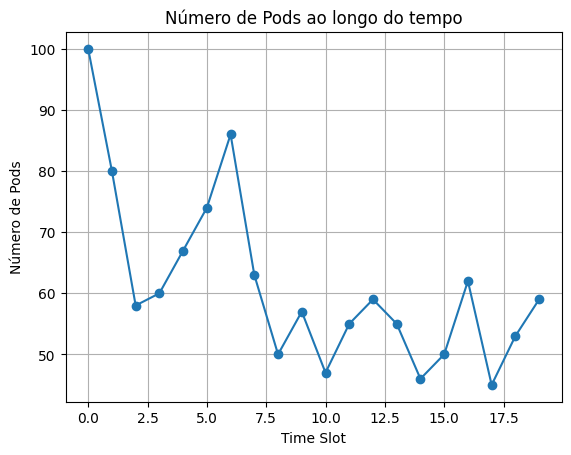

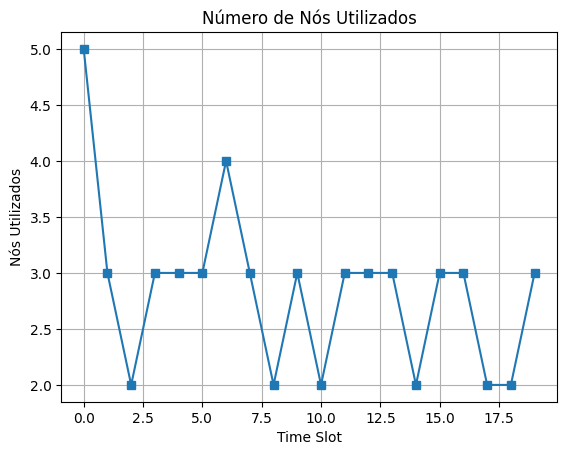

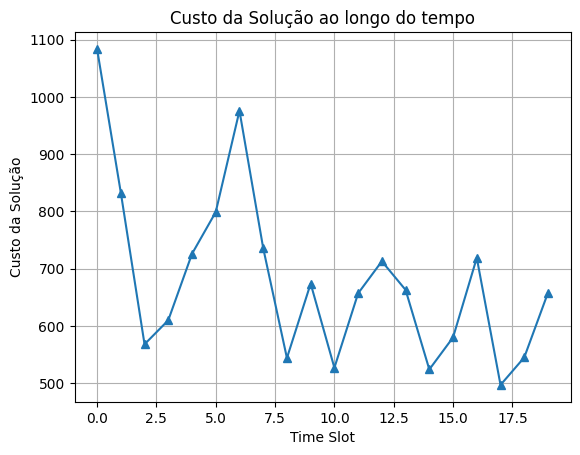

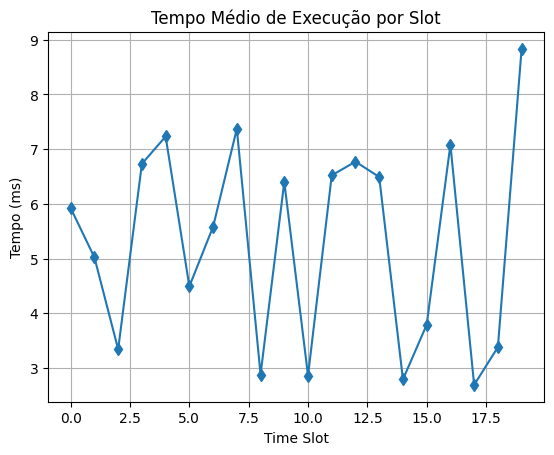

In [6]:
# Reimportar dependências após reset
import pandas as pd
import matplotlib.pyplot as plt

# Carregar os dados do CSV
df = pd.read_csv("formulation.csv", delimiter=";")

# Plotar número de pods ao longo do tempo
plt.figure()
plt.plot(df["time slot"], df["number of pods"], marker="o")
plt.title("Número de Pods ao longo do tempo")
plt.xlabel("Time Slot")
plt.ylabel("Número de Pods")
plt.grid(True)
plt.show()

# Plotar número de nós utilizados
plt.figure()
plt.plot(df["time slot"], df["usedNodes"], marker="s")
plt.title("Número de Nós Utilizados")
plt.xlabel("Time Slot")
plt.ylabel("Nós Utilizados")
plt.grid(True)
plt.show()

# Plotar custo da solução
plt.figure()
plt.plot(df["time slot"], df["solution cost"], marker="^")
plt.title("Custo da Solução ao longo do tempo")
plt.xlabel("Time Slot")
plt.ylabel("Custo da Solução")
plt.grid(True)
plt.show()

# Plotar tempo de execução
plt.figure()
plt.plot(df["time slot"], df["time (ms)"], marker="d")
plt.title("Tempo Médio de Execução por Slot")
plt.xlabel("Time Slot")
plt.ylabel("Tempo (ms)")
plt.grid(True)
plt.show()


In [1]:
import gurobipy as gp
from gurobipy import GRB

# Conjuntos
pods = ['p1', 'p2', 'p3']
nodes = ['n1', 'n2']
times = [1, 2, 3]

# Parâmetros
u = {'p1': 3, 'p2': 2, 'p3': 4}  # demanda dos pods
U = {'n1': 6, 'n2': 6}          # capacidade dos nós

# Custo de alocação
c = {
    ('n1', 'p1'): 5, ('n1', 'p2'): 4, ('n1', 'p3'): 6,
    ('n2', 'p1'): 6, ('n2', 'p2'): 3, ('n2', 'p3'): 7
}

# Custo de migração
m = {
    ('n1', 'n1'): 0, ('n1', 'n2'): 10,
    ('n2', 'n1'): 10, ('n2', 'n2'): 0
}

# Modelo
model = gp.Model("PodAllocationWithMigration")

# Variáveis de alocação
y = model.addVars(nodes, pods, times, vtype=GRB.BINARY, name="y")

# Variáveis de migração
z = model.addVars(nodes, nodes, pods, times[1:], vtype=GRB.BINARY, name="z")

# Cada pod alocado exatamente uma vez por tempo
for t in times:
    for p in pods:
        model.addConstr(gp.quicksum(y[n, p, t] for n in nodes) == 1)

# Capacidade dos nós
for t in times:
    for n in nodes:
        model.addConstr(gp.quicksum(u[p] * y[n, p, t] for p in pods) <= U[n])

# Definição das variáveis de migração
for t in times[1:]:
    for i in nodes:
        for k in nodes:
            for p in pods:
                model.addConstr(z[i, k, p, t] >= y[i, p, t - 1] + y[k, p, t] - 1)

# Função objetivo
allocation_cost = gp.quicksum(c[n, p] * y[n, p, t] for n in nodes for p in pods for t in times)
migration_cost = gp.quicksum(m[i, k] * z[i, k, p, t] for i in nodes for k in nodes for p in pods for t in times[1:])

model.setObjective(allocation_cost + migration_cost, GRB.MINIMIZE)

# Otimizar
model.optimize()

# Imprimir solução
if model.status == GRB.OPTIMAL:
    print("\nSolução ótima encontrada:\n")
    for t in times:
        for p in pods:
            for n in nodes:
                if y[n, p, t].X > 0.5:
                    print(f"Tempo {t}: Pod {p} alocado no nó {n}")


Set parameter Username
Academic license - for non-commercial use only - expires 2026-04-03
Gurobi Optimizer version 11.0.3 build v11.0.3rc0 (mac64[arm] - Darwin 24.4.0 24E248)

CPU model: Apple M2 Max
Thread count: 12 physical cores, 12 logical processors, using up to 12 threads

Optimize a model with 39 rows, 42 columns and 108 nonzeros
Model fingerprint: 0x760dadc3
Variable types: 0 continuous, 42 integer (42 binary)
Coefficient statistics:
  Matrix range     [1e+00, 4e+00]
  Objective range  [3e+00, 1e+01]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 6e+00]
Found heuristic solution: objective 68.0000000
Presolve removed 39 rows and 42 columns
Presolve time: 0.00s
Presolve: All rows and columns removed

Explored 0 nodes (0 simplex iterations) in 0.00 seconds (0.00 work units)
Thread count was 1 (of 12 available processors)

Solution count 2: 45 68 

Optimal solution found (tolerance 1.00e-04)
Best objective 4.500000000000e+01, best bound 4.500000000000e+01, gap 0.0000